<div style="text-align: center; margin-bottom: 25px;">
    <img src="https://upload.wikimedia.org/wikipedia/fr/8/86/Logo_CentraleSupélec.svg?utm_source=fr.wikipedia.org&utm_campaign=imageinfo&utm_content=original" width="200" style="margin-bottom: 20px;">
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Airbnb price prediction in Paris</h1>
    </div>
</div>

## **1. Module imports**

In [2]:
import json

import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap as LSC

from sklearn.base import clone
from sklearn.base import BaseEstimator
from sklearn.base import RegressorMixin

from sklearn.metrics import r2_score
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import KFold
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance

from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

## **2. Data cleaning**

Download the data first with `python data.py`.

In [3]:
listings = pd.read_csv("data/listings.csv.gz")

listings.head (4)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3109,https://www.airbnb.com/rooms/3109,20260916052215,2026-09-19,NaN,zen and calm,Lovely Appartment with one bedroom with a Quee...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,3631,...,5.00,5.00,4.90,7511409139079,NaN,1,1,0,0,0.09
1,7397,https://www.airbnb.com/rooms/7397,20260916052215,2026-09-22,NaN,MARAIS - 2ROOMS APT - 2/4 PEOPLE,"VERY CONVENIENT, WITH THE BEST LOCATION !",NaN,https://a0.muscache.com/pictures/67928287/330b...,2626,...,4.90,4.94,4.74,7510400829623,NaN,1,1,0,0,2.14
2,9952,https://www.airbnb.com/rooms/9952,20260916052215,2026-09-21,NaN,Paris petit coin douillet,"I am a retired lady, who offers a pleasant lit...",NaN,https://a0.muscache.com/pictures/ae822d16-74d2...,33534,...,4.87,4.87,4.88,7511101582862,NaN,1,1,0,0,0.36
3,11265,https://www.airbnb.com/rooms/11265,20260916052215,2026-09-22,NaN,Elegant appartment in Montmartre,"Located in lively and charming Montmartre, pla...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,41718,...,4.90,4.96,4.85,7511801401834,NaN,1,1,0,0,0.38


- Sample Airbnb listing excerpt

In [4]:
listings[["listing_url", "price", "accommodates", "bathrooms_text", "neighbourhood_cleansed"]].loc [67803]

listing_url               https://www.airbnb.com/rooms/1564585568174337999
price                                                            $1,631.25
accommodates                                                            10
bathrooms_text                                                     5 baths
neighbourhood_cleansed                                          Luxembourg
Name: 67803, dtype: object

- List of available features. We will then select the most relevant ones.

In [5]:
print (listings.shape)
listings.columns.to_list ()

(77149, 90)


['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_profile_id',
 'host_profile_url',
 'host_name',
 'host_since',
 'hosts_time_as_user_years',
 'hosts_time_as_user_months',
 'hosts_time_as_host_years',
 'hosts_time_as_host_months',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote

### **2.1. Variable selection**

- We drop columns containing only missing values.

In [6]:
df = listings.dropna (axis = 1, how = "all")
df.shape

(77149, 76)

- We drop features containing URLs (not usable as is), non-informative features, and features only available after the listing is published.

In [7]:
links = ["listing_url", 
        "picture_url", 
        "host_url", 
        "host_profile_url", 
        "host_picture_url"]

useless = ["source", 
           "calendar_last_scraped", 
           "scrape_id", "last_scraped", 
           "host_profile_id", 
           "host_name", 
           "host_about", 
           "host_location"]

post = ['availability_30', 
        'availability_60', 
        'availability_90', 
        'availability_365',
        'number_of_reviews_l30d', 
        'availability_eoy', 
        'number_of_reviews_ly', 
        'review_scores_accuracy', 
        'review_scores_checkin', 
        'review_scores_communication', 
        'review_scores_value', 
        'first_review', 
        'last_review', 
        'reviews_per_month', 
        'estimated_occupancy_l365d', 
        'has_availability', 
        "number_of_reviews_ltm", 
        "number_of_reviews", 
        "review_scores_rating",
        "review_scores_cleanliness",
        "review_scores_location"]

df = df.drop (columns = links)
df = df.drop (columns = useless)
df = df.drop (columns = post)

df.shape

(77149, 42)

- We drop features causing data leakage as well as redundant features.

In [8]:
leaks = ["price_quote_checkin_date", 
         "price_quote_checkout_date", 
         "price_quote_total_price", 
         "price_quote_price_per_night", 
         "price_quote_raw", 
         "estimated_revenue_l365d"]

duplicates = ["minimum_minimum_nights", 
            "maximum_minimum_nights", 
            "minimum_maximum_nights", 
            "maximum_maximum_nights", 
            "minimum_nights_avg_ntm", 
            "maximum_nights_avg_ntm", 
            "calculated_host_listings_count", 
            "calculated_host_listings_count_entire_homes", 
            "calculated_host_listings_count_private_rooms", 
            "calculated_host_listings_count_shared_rooms"]


df = df.drop (columns = leaks)
df = df.drop (columns = duplicates)

df.shape

(77149, 26)

- We only keep the number of years since the host joined Airbnb.

In [9]:
old = ["hosts_time_as_user_years", 
          "hosts_time_as_user_months", 
          "hosts_time_as_host_years", 
          "hosts_time_as_host_months"]

df.loc [:, "time_as_host"] = df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"]/12
df = df.drop (columns = old)

df.shape

(77149, 23)

- We drop the number of beds, highly correlated with guest capacity and accounting for 97% of missing values, as well as the few remaining rows with missing values.

In [10]:
a = df[["beds", "accommodates"]].corr ("spearman")["beds"]["accommodates"]
print (f"Spearman correlation : {a:.2f}")

df = df.drop (columns = "beds")

df.shape

Spearman correlation : 0.82


(77149, 22)

- We convert the nightly price to a numeric type.

In [11]:
df["price"] = df["price"].str.replace("$", "").str.replace (",", "").astype (float)

### **2.2. Population selection**

- We drop listings with no price.

In [12]:
noprice = df["price"].notna ()
df = df.loc [noprice]

df.shape

(43537, 22)

- We only keep listings with a minimum stay of less than 30 nights to exclude disguised long-term rentals.

In [13]:
nights = df["minimum_nights"] < 30
df = df.loc [nights]

print (df.shape)

(37635, 22)


- Some hosts set unrealistic prices instead of deactivating their listing. Most of these exceed €800 per night per person, so we drop listings above €700.
- Likewise, we drop the few suspiciously cheap listings below €14 per night per person.

In [14]:
high_price = (df["price"] / df ["accommodates"]) < 700
low_price = (df["price"] / df["accommodates"]) > 14

df = df.loc [high_price]
df = df.loc [low_price]

df.shape

(37416, 22)

In [15]:
good_bedrooms = df["bedrooms"].notna ()
good_bathrooms = df["bathrooms_text"].notna ()

df = df.loc [good_bedrooms]
df = df.loc [good_bathrooms]

df.shape

(37367, 22)

### **2.3. Features engineering**

- We convert boolean features originally encoded as t/f into 1/0.

In [16]:
superhost = df["host_is_superhost"] == "t"
df["host_is_superhost"] = superhost.astype (int)

profil_pic = df["host_has_profile_pic"] == "t"
df["host_has_profile_pic"] = profil_pic.astype (int)

identity_verified = df["host_identity_verified"] == "t"
df["host_identity_verified"] = identity_verified.astype (int)

- We create one feature for the number of bathrooms and a binary feature indicating whether the bathroom is shared.

In [17]:
text = df["bathrooms_text"].str.lower()

df["nb_bathrooms"] = text.str.extract(r"(\d+\.?\d*)")[0].astype(float)
df.loc[text.str.contains("half"), "nb_bathrooms"] = 0.5
df.loc[text == "no bathroom", "nb_bathrooms"] = 0

df["bathroom_shared"] = text.str.contains("shared").astype(int)

df = df.drop(columns="bathrooms_text")

We replace the license number, almost unique and therefore unusable as is, with three binary features:
- No license: 1 if the listing has no license number, 0 otherwise.
- Hotel exemption: 1 if the listing declares a hotel exemption consistent with its property type (hotel, aparthotel), 0 otherwise.
- Inconsistent declaration: 1 if the declaration is inconsistent (shared or non-Parisian number, mobility lease under 30 nights, hotel exemption on a regular home), 0 otherwise.


In [18]:
lic = df["license"]

missing    = lic.isna()
exempt     = lic.str.contains("Exempt", na=False)
mobility   = lic.str.contains("mobility", na=False)
number     = lic.str.isdigit().fillna(False).astype(bool)
share    = lic.map(lic.value_counts()).fillna(0) > 1
outside_paris = number & ~lic.str.startswith("75", na=False)
type_hotel = df["property_type"].str.contains("hotel|serviced", case=False, na=False)

df["licence_absente"]  = missing.astype(int)
df["licence_hotel"]    = (exempt & type_hotel).astype(int)
df["licence_suspecte"] = ((number & (share | outside_paris))
                          | mobility
                          | (exempt & ~type_hotel)).astype(int)

df = df.drop(columns="license")
df.shape

(37367, 25)

- We create a feature counting the number of amenities in the apartment.

In [19]:
ameni = df["amenities"].apply(json.loads)

ameni_explode = ameni.explode()

comptes = ameni_explode.value_counts()
#comptes.head (10)

In [20]:
df["nb_amenities"] = ameni.apply(len)
df.shape

(37367, 26)

- We select which amenities to turn into features among the most common ones, using intuition and common sense.

In [21]:
equipements = {"conditioning":             r"air conditioning|\bac\b", 
               "elevator":        r"elevator",
               "washer":       r"(?<!dish)washer",
               "dish_washer":   r"dishwasher",
               "balcony":  r"balcony|patio|terrace",
               "view":              r"view",
               "parking":          r"parking",
               "workspace":   r"workspace",
               "self_checking": r"self check-in",
               "pets":          r"pets allowed",}

texte_amen = ameni.apply(lambda l: " | ".join(l).lower())

for col, motif in equipements.items():
    df[col] = texte_amen.str.contains(motif, regex=True).astype(int)

df = df.drop (columns = "amenities")
df.shape

(37367, 35)

- We replace the property type (55 categories, many of them very rare) with a building type grouping listings into 6 categories: apartment, house, loft, hotel, bed and breakfast, other.

In [22]:
pt = df["property_type"].str.lower()

conditions = [pt.str.contains("hotel|serviced"), 
              pt.str.contains("bed and breakfast|guesthouse|hostel|casa particular"), 
              pt.str.contains("loft"), 
              pt.str.contains("rental unit|condo|guest suite|entire place|home/apt") | (pt == "private room"), 
              pt.str.contains("townhouse|villa|vacation home|home")] 
              
categories = ["hotel", "chambre_hotes", "loft", "appartement", "maison"]

df["type_batiment"] = np.select(conditions, categories, default="autre")

df = df.drop(columns="property_type")
df.shape

(37367, 35)

### **2.4. Outlier removal**

- Bathrooms: after reviewing listings with many bathrooms, most look genuine, with up to 7 bathrooms for luxury properties. We only drop two clear outliers: 42 and 19 bathrooms for 2 guests.

In [23]:
print (df["nb_bathrooms"].sort_values ().tail (4))

df = df.drop (55390)
df = df.drop (56230)

df.shape

39821     7.0
60707     7.5
56230    19.0
55390    42.0
Name: nb_bathrooms, dtype: float64


(37365, 35)

- Bedrooms: after reviewing listings with many bedrooms, we drop two with an abnormally high count, most likely data entry errors by the host.

In [24]:
print (df["bedrooms"].sort_values ().tail (4))

df = df.drop (22694)
df = df.drop (22801)

df.shape

35837    11.0
69374    12.0
22801    33.0
22694    33.0
Name: bedrooms, dtype: float64


(37363, 35)

- Maximum stay: we cap the maximum number of nights at 1,125, Airbnb’s own limit, to remove outliers.

In [25]:
df["maximum_nights"] = df["maximum_nights"].clip(upper=1125)

- Final adjustments

In [26]:
df["description"] = df["description"].fillna ("")
df = df.reset_index (drop = True)

- We save the cleaned dataset.

In [27]:
df.to_parquet("data/clean.parquet")

## **3. Data exploration**

In [28]:
df = pd.read_parquet ("clean.parquet")

#### **3.1. Price distribution**

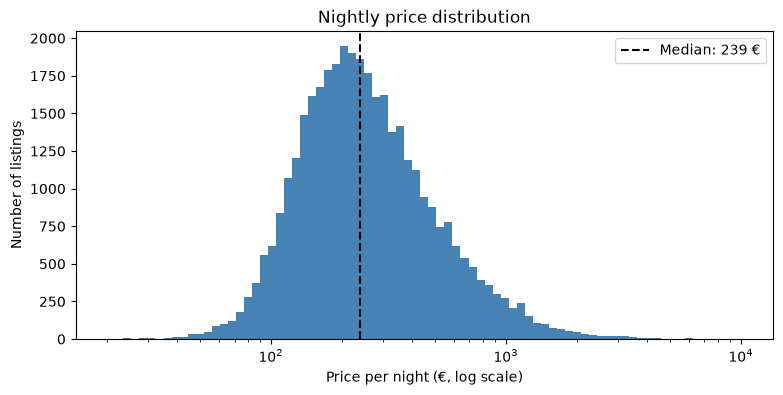

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
prix = df['price']
bins = np.logspace(np.log10(prix.min()), np.log10(prix.max()), 80)
ax.hist(prix, bins=bins, color="steelblue")
ax.set_xscale("log")
ax.axvline(prix.median(), color="black", linestyle="--", label=f"Median: {prix.median():.0f} €")
ax.set(title="Nightly price distribution", xlabel="Price per night (€, log scale)", ylabel="Number of listings")
ax.legend()
plt.show()

#### **3.2. Listing prices across Paris**

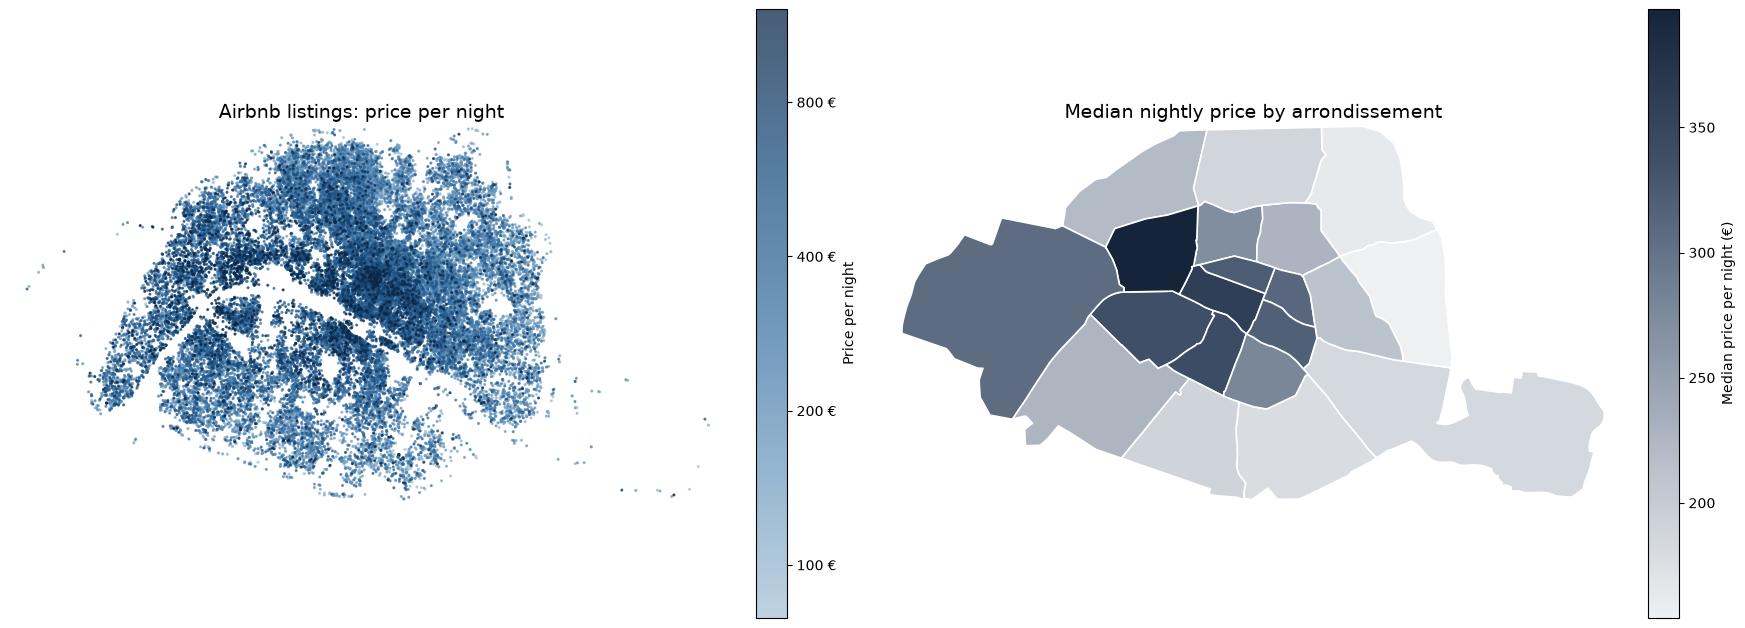

In [30]:
seine = LSC.from_list("seine", ["#a9c4d8", "#6f9cc0", "#3d73a3", "#1d4f80", "#0a2747"])
zinc  = LSC.from_list("zinc",  ["#eef0f2", "#b8c0ca", "#7d8a9c", "#3f5068", "#16243a"])

quartiers = gpd.read_file("data/neighbourhoods.geojson").to_crs(2154)
pts = (gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs=4326)
         .to_crs(2154).assign(log_prix=lambda d: np.log(d.price)).sort_values("log_prix"))
vmin, vmax = pts.log_prix.quantile([0.02, 0.98])
carte = quartiers.merge(df.groupby("neighbourhood_cleansed").price.median().rename("prix_median"),
                        left_on="neighbourhood", right_index=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))

sc = ax1.scatter(pts.geometry.x, pts.geometry.y, c=pts.log_prix, cmap=seine,
                 s=1.5, alpha=0.75, vmin=vmin, vmax=vmax)
ticks = [50, 100, 200, 400, 800]
fig.colorbar(sc, ax=ax1, shrink=0.7, label="Price per night",
             ticks=np.log(ticks)).set_ticklabels([f"{t} €" for t in ticks])

carte.plot(column="prix_median", cmap=zinc, edgecolor="white", linewidth=1.2, ax=ax2,
           legend=True, legend_kwds={"label": "Median price per night (€)", "shrink": 0.7})

xmin, ymin, xmax, ymax = quartiers.total_bounds
for ax, titre in [(ax1, "Airbnb listings: price per night"),
                  (ax2, "Median nightly price by arrondissement")]:
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal")
    ax.set_title(titre, fontsize=14); ax.set_axis_off()

plt.tight_layout()
plt.show()

#### **3.3. Impact of amenities on price**

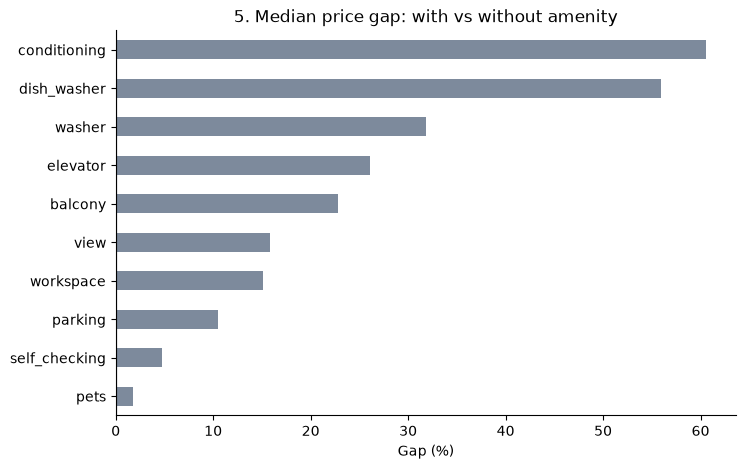

In [31]:
eq_cols = ["conditioning", "elevator", "washer", "dish_washer", "balcony",
           "view", "parking", "workspace", "self_checking", "pets"]

ecart = pd.Series({c: (df.loc[df[c] == 1, "price"].median() / df.loc[df[c] == 0, "price"].median() - 1) * 100 for c in eq_cols}, dtype=float).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ecart.plot(kind="barh", ax=ax, color="#7d8a9c")
ax.axvline(0, color="#16243a", linewidth=0.8)
ax.set(title="5. Median price gap: with vs without amenity", xlabel="Gap (%)", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## **4. Data preparation**

- We preselect the target variable and the columns needed later on (not used directly by the model).

In [32]:
target = ["price"]
text = ["name", "description"]
identifiers = ["id", "host_id"]

excluded = target + identifiers  + text
variables = [c for c in df.columns if c not in excluded]

- We split the dataset into a train set (80%) and a test set (20%) using GroupShuffleSplit, so that all listings from the same host stay in the same set.

In [33]:
X = df[variables]
y = np.log (df['price'])
groupes = df['host_id']

gss = GroupShuffleSplit (1, test_size = 0.2, random_state = 1)
idx_train, idx_test = next (gss.split (X, y, groups = groupes))

X_train = X.iloc [idx_train]
X_test = X.iloc [idx_test]
y_train = y.iloc [idx_train]
y_test = y.iloc [idx_test]
groupes_train = groupes.iloc [idx_train]
groupes_test = groupes.iloc [idx_test]

print (f"X_train.shape : {X_train.shape} \ny_test.shape = {y_test.shape}")

X_train.shape : (29807, 30) 
y_test.shape = (7556,)


- We prepare the data upstream of the pipeline.

In [34]:
cat_cols = ["neighbourhood_cleansed", "room_type", "type_batiment"]
num_cols = [c for c in X_train.columns if c not in cat_cols]


preparation_distance = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols), 
                                          ("num", StandardScaler(), num_cols)])

preparation_no_distance = ColumnTransformer ([("cat", OneHotEncoder (handle_unknown = "ignore"), cat_cols),
                                              ("num", "passthrough", num_cols)])

cv = GroupKFold (n_splits = 5)

- We define the evaluation metrics.

In [35]:
def mae_euro (ytrue, ypred):
    mae = np.abs (np.exp (ytrue) - np.exp (ypred))
    mae = np.mean (mae)
    return mae


my_scorer = make_scorer (mae_euro, greater_is_better = False)
scoring = {"rmse_log": "neg_root_mean_squared_error", "mae": my_scorer, "r2": "r2"}

## **5. Baselines**

Two baseline levels:
- Overall median price
- Median price by arrondissement

#### **5.1. Overall median price**

In [36]:
baseline1 = DummyRegressor (strategy = "median")

score = cross_validate (baseline1, 
                        X_train, 
                        y_train, 
                        groups = groupes_train, 
                        cv = cv, 
                        scoring = scoring)

log_rmse = -score["test_rmse_log"]
mae = -score ["test_mae"]
R2 = score ["test_r2"]

print(f"RMSE log : {log_rmse.mean():.3f} ± {log_rmse.std():.3f}")
print(f"MAE      : {mae.mean():.1f} € ± {mae.std():.1f} €")
print(f"R²       : {R2.mean():.3f} ± {R2.std():.3f}")

RMSE log : 0.682 ± 0.026
MAE      : 174.8 € ± 13.2 €
R²       : -0.014 ± 0.009


#### **5.2. Median price by arrondissement**

In [37]:
class Baseline2 (BaseEstimator, RegressorMixin):
    
    def __init__(self, colonne="neighbourhood_cleansed"):
        self.colonne = colonne

    def fit(self, X, y):
        self.medianes_ = y.groupby(X[self.colonne]).median()
        self.mediane_globale_ = y.median()
        return self

    def predict(self, X):
        pred = X[self.colonne].map(self.medianes_)
        return pred.fillna(self.mediane_globale_).to_numpy()

In [38]:
baseline2 = Baseline2 ()

score = cross_validate (baseline2, 
                        X_train, 
                        y_train, 
                        groups = groupes_train, 
                        cv = cv, 
                        scoring = scoring)


log_rmse = -score["test_rmse_log"]
mae = -score ["test_mae"]
R2 = score ["test_r2"]

print(f"RMSE log : {log_rmse.mean():.3f} ± {log_rmse.std():.3f}")
print(f"MAE      : {mae.mean():.1f} € ± {mae.std():.1f} €")
print(f"R²       : {R2.mean():.3f} ± {R2.std():.3f}")

RMSE log : 0.627 ± 0.021
MAE      : 163.4 € ± 11.6 €
R²       : 0.144 ± 0.006


## **6. Ridge regression**

#### **6.1. Pipeline**

In [39]:
ridge = Ridge ()

pipeline = Pipeline ([("preparation", preparation_distance), 
                      ("ridge", ridge)])

parameters = {"ridge__alpha": np.logspace(-3, 3, 25)}

grid_ridge = GridSearchCV (pipeline, 
                           parameters, 
                           cv = cv, 
                           scoring = scoring, 
                           refit = "rmse_log", 
                           return_train_score = True, 
                           n_jobs = -1)

grid_ridge.fit (X_train, y_train, groups = groupes_train)

res = pd.DataFrame(grid_ridge.cv_results_)
best = res.loc[grid_ridge.best_index_]

print(f"RMSE log : {-best['mean_test_rmse_log']:.3f} ± {best['std_test_rmse_log']:.3f}")
print(f"MAE      : {-best['mean_test_mae']:.1f} € ± {best['std_test_mae']:.1f} €")
print(f"R²       : {best['mean_test_r2']:.3f} ± {best['std_test_r2']:.3f}")

RMSE log : 0.435 ± 0.008
MAE      : 118.1 € ± 8.3 €
R²       : 0.587 ± 0.021


#### **6.2. Learning curves**

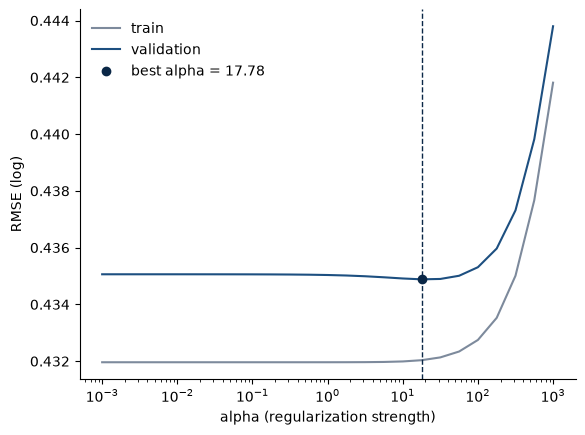

In [40]:
x  = res["param_ridge__alpha"]
tr = -res["mean_train_rmse_log"]
va = -res["mean_test_rmse_log"]
alpha  = grid_ridge.best_params_["ridge__alpha"]
vb = -best["mean_test_rmse_log"]

plt.plot(x, tr, color="#7d8a9c", label="train")
plt.plot(x, va, color="#1d4f80", label="validation")
plt.axvline(alpha, color="#0a2747", linestyle="--", linewidth=1)
plt.plot(alpha, vb, "o", color="#0a2747", markersize=6, label=f"best alpha = {alpha:.2f}")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.xscale("log")
plt.xlabel("alpha (regularization strength)"); plt.ylabel("RMSE (log)")
plt.legend(frameon=False)
plt.show()

## **7. K-nearest neighbors**

#### **7.1. Model training**

In [41]:
knn = KNeighborsRegressor ()

pipeline = Pipeline ([("preparation", preparation_distance), ("knn", knn)])

parameters = {"knn__n_neighbors" : [15, 17, 19, 21, 23, 25, 26, 27, 28, 29, 30, 40, 60, 80, 100]}
              
grid_knn = GridSearchCV (pipeline, 
                         parameters,
                         scoring = scoring,
                         n_jobs = -1,
                         refit = "rmse_log",
                         cv = cv,
                         verbose = 0,
                         return_train_score = True)

grid_knn.fit (X_train, y_train, groups = groupes_train)


res = pd.DataFrame(grid_knn.cv_results_)
best = res.loc[grid_knn.best_index_]

print(f"RMSE log : {-best['mean_test_rmse_log']:.3f} ± {best['std_test_rmse_log']:.3f}")
print(f"MAE      : {-best['mean_test_mae']:.1f} € ± {best['std_test_mae']:.1f} €")
print(f"R²       : {best['mean_test_r2']:.3f} ± {best['std_test_r2']:.3f}")

RMSE log : 0.466 ± 0.013
MAE      : 121.9 € ± 8.2 €
R²       : 0.526 ± 0.015


#### **7.2. Learning curves**

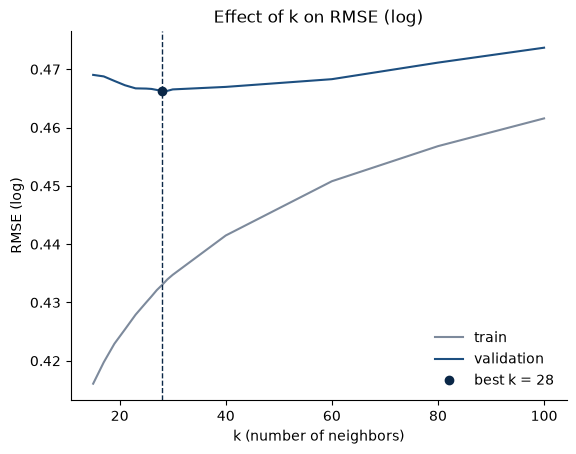

In [42]:
x  = res["param_knn__n_neighbors"]
tr = -res["mean_train_rmse_log"]
va = -res["mean_test_rmse_log"]
k  = grid_knn.best_params_["knn__n_neighbors"]
vb = -best["mean_test_rmse_log"]

plt.plot(x, tr, color="#7d8a9c", label="train")
plt.plot(x, va, color="#1d4f80", label="validation")
plt.axvline(k, color="#0a2747", linestyle="--", linewidth=1)
plt.plot(k, vb, "o", color="#0a2747", markersize=6, label=f"best k = {k}")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.xlabel("k (number of neighbors)"); plt.ylabel("RMSE (log)")
plt.legend(frameon=False)
plt.title ("Effect of k on RMSE (log)")
plt.show()

## **8. Random forest**

#### **8.1. Model training**

In [43]:
rf = RandomForestRegressor (n_estimators = 400, random_state = 1)

pipeline = Pipeline ([("preparation", preparation_no_distance), ("rf", rf)])

parameters = {"rf__max_features": [0.15, 0.2],
              "rf__min_samples_leaf": [2, 3]}

grid_rf = GridSearchCV (pipeline, 
                        parameters,
                        scoring = scoring,
                        n_jobs = -1,
                        refit = "rmse_log",
                        cv = cv,
                        return_train_score = True)

grid_rf.fit (X_train, y_train, groups = groupes_train)


res = pd.DataFrame(grid_rf.cv_results_)
best = res.loc[grid_rf.best_index_]

print(f"RMSE log : {-best['mean_test_rmse_log']:.3f} ± {best['std_test_rmse_log']:.3f}")
print(f"MAE      : {-best['mean_test_mae']:.1f} €")
print(f"R²       : {best['mean_test_r2']:.3f}")
print(f"Temps    : {best['mean_fit_time']:.2f} s per training run")

RMSE log : 0.408 ± 0.011
MAE      : 108.8 €
R²       : 0.637
Temps    : 15.88 s per training run


## **9. Gradient boosting**

#### **9.1. Model training**

In [44]:
xgb = XGBRegressor(n_estimators=600, subsample=0.8, colsample_bytree=0.8, random_state=1, n_jobs=1)

pipeline = Pipeline ([("preparation", preparation_no_distance), ("xgb", xgb)])

parameters = {"xgb__learning_rate": [0.03, 0.1],
              "xgb__max_depth": [4, 6, 8],
              "xgb__n_estimators": [300, 600]}

grid_xgb = GridSearchCV (pipeline,
                         parameters,
                         scoring = scoring,
                         n_jobs = -1,
                         refit = "rmse_log",
                         cv = cv,
                         return_train_score = True)

grid_xgb.fit (X_train, y_train, groups = groupes_train)

res = pd.DataFrame (grid_xgb.cv_results_)
best = res.loc [grid_xgb.best_index_]

print(f"RMSE log : {-best['mean_test_rmse_log']:.3f} ± {best['std_test_rmse_log']:.3f}")
print(f"MAE      : {-best['mean_test_mae']:.1f} €")
print(f"R²       : {best['mean_test_r2']:.3f}")
print(f"Temps    : {best['mean_fit_time']:.2f} s per training run")

RMSE log : 0.397 ± 0.011
MAE      : 106.2 €
R²       : 0.656
Temps    : 2.09 s per training run


#### **9.2. Model performance**

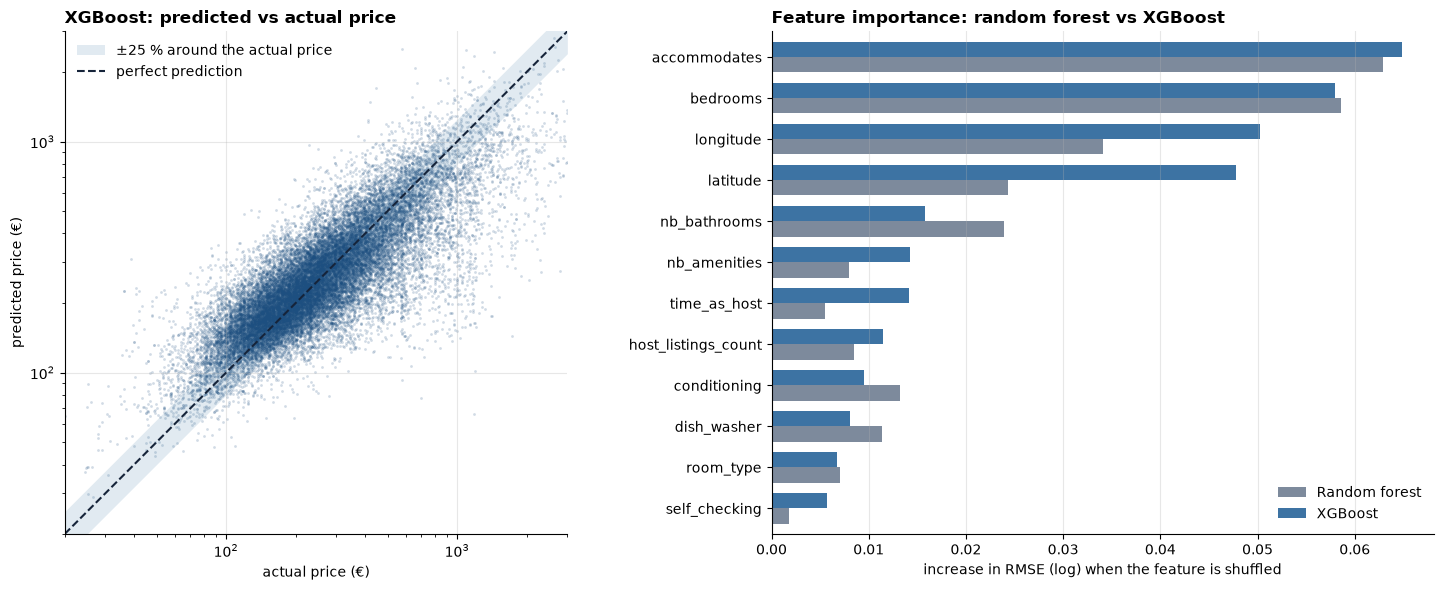

In [45]:
idx_app, idx_val = next(cv.split(X_train, y_train, groupes_train))
X_app, X_val = X_train.iloc[idx_app], X_train.iloc[idx_val]
y_app, y_val = y_train.iloc[idx_app], y_train.iloc[idx_val]

pred = cross_val_predict(grid_xgb.best_estimator_, X_train, y_train,
                         groups=groupes_train, cv=cv, n_jobs=-1)

importances = {}
for nom, g in [("Random forest", grid_rf), ("XGBoost", grid_xgb)]:
    m = clone(g.best_estimator_).fit(X_app, y_app)
    p = permutation_importance(m, X_val, y_val, scoring="neg_root_mean_squared_error",
                               n_repeats=5, random_state=1, n_jobs=-1)
    importances[nom] = p.importances_mean
imp = pd.DataFrame(importances, index=X_train.columns).sort_values("XGBoost").tail(12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

x = np.array([20, 3000])
ax1.fill_between(x, x / 1.25, x * 1.25, color="#a9c4d8", alpha=0.35, lw=0, label="±25 % around the actual price")
ax1.scatter(np.exp(y_train), np.exp(pred), s=4, alpha=0.2, color="#1d4f80", lw=0)
ax1.plot(x, x, "--", color="#16243a", lw=1.5, label="perfect prediction")
ax1.set(xscale="log", yscale="log", xlim=x, ylim=x, box_aspect=1)
ax1.set_xlabel("actual price (€)"); ax1.set_ylabel("predicted price (€)")
ax1.set_title("XGBoost: predicted vs actual price", loc="left", fontweight="bold")
ax1.spines[["top", "right"]].set_visible(False); ax1.grid(alpha=0.3); ax1.legend(frameon=False)

imp.plot.barh(ax=ax2, color=["#7d8a9c", "#3d73a3"], width=0.75)
ax2.set_xlabel("increase in RMSE (log) when the feature is shuffled")
ax2.set_title("Feature importance: random forest vs XGBoost", loc="left", fontweight="bold")
ax2.spines[["top", "right"]].set_visible(False); ax2.grid(axis="x", alpha=0.3); ax2.legend(frameon=False)

plt.tight_layout()
plt.show()

## **10. Validating the host grouping hypothesis**

In [47]:
cv_random = KFold (n_splits = 5, shuffle = True, random_state = 1)

grid_random = GridSearchCV (pipeline,
                            parameters,
                            scoring = scoring,
                            n_jobs = -1,
                            refit = "rmse_log",
                            cv = cv_random)

grid_random.fit (X_train, y_train)

res = pd.DataFrame (grid_random.cv_results_)
best = res.loc [grid_random.best_index_]

print(f"RMSE log : {-best['mean_test_rmse_log']:.3f} ± {best['std_test_rmse_log']:.3f}")
print(f"MAE      : {-best['mean_test_mae']:.1f} €")
print(f"R²       : {best['mean_test_r2']:.3f}")

RMSE log : 0.374 ± 0.002
MAE      : 98.5 €
R²       : 0.696


Without host-based splitting, the model gains 4 points of R² and reaches an RMSE (log) of 0.374 instead of 0.397, overestimating its performance by about 6%. This confirms the need to group by host.

## **11. Final evaluation**

In [48]:
modeles = {"Overall median": DummyRegressor(strategy="median").fit(X_train, y_train),
           "Median by arrondissement": Baseline2().fit(X_train, y_train),
           "XGBoost": grid_xgb.best_estimator_,}

lines = []
for nom, modele in modeles.items():
    pred = modele.predict(X_test)
    lines.append({"model":       nom,
                   "RMSE (log)": root_mean_squared_error(y_test, pred),
                   "MAE (€)":    mean_absolute_error(np.exp(y_test), np.exp(pred)),
                   "R²":         r2_score(y_test, pred)})

pd.DataFrame(lines).round(3)

,model,RMSE (log),MAE (€),R²
0,Overall median,0.649,162.919,-0.017
1,Median by arrondissement,0.606,152.660,0.114
2,XGBoost,0.391,102.373,0.630
